# Checkpoint 1: Tiền Xử Lý và Chuẩn Hóa Dữ Liệu (Data Preprocessing)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu: Khắc phục hạn chế của pipeline tiền xử lý gốc (loại bỏ stopwords và deEmojify), bảo tồn đối tượng công kích (đại từ nhân xưng), từ phủ định, và sắc thái cảm xúc (emoji 2 pha), kết hợp chuẩn hóa teencode và phân đoạn từ PyVi.

Ghi chú: Toàn bộ mã nguồn tiền xử lý, định nghĩa Dataset và đo lường đánh giá được tích hợp trực tiếp trong notebook nhằm đảm bảo khả năng thực thi độc lập trên Google Colab mà không phụ thuộc module bên ngoài. Các tài nguyên từ điển chuẩn hóa được cấu hình từ các tệp riêng biệt (data/teencode.csv và data/emojis.csv).

In [18]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint01')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint01')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint01
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint01


In [19]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q pyvi transformers accelerate scikit-learn seaborn matplotlib

In [20]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Thiết lập random seed thành công: {random_seed}')

Thiết lập random seed thành công: 42


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

In [21]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

print(f'Đọc tập Train từ: {train_path}')
print(f'Đọc tập Dev từ:   {dev_path}')
print(f'Đọc tập Test từ:  {test_path}')

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

# Kiểm tra toàn vẹn số lượng mẫu và giá trị thiếu trước khi đưa vào pipeline
assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, giá trị thiếu free_text: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, giá trị thiếu free_text: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, giá trị thiếu free_text: {test_raw["free_text"].isna().sum()}')

Đọc tập Train từ: data/train.csv
Đọc tập Dev từ:   data/dev.csv
Đọc tập Test từ:  data/test.csv
Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, giá trị thiếu free_text: 2
- Dev:   2672 mẫu, giá trị thiếu free_text: 0
- Test:  6680 mẫu, giá trị thiếu free_text: 0


## 2. Định Nghĩa Trực Tiếp Lớp Tiền Xử Lý ViHSDPreprocessor

In [22]:
import os
import re
import pandas as pd
import numpy as np

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:
    """Bộ tiền xử lý và chuẩn hóa văn bản cho bài toán phát hiện phát ngôn thù ghét (ViHSD).

    Quy trình xử lý bao gồm:
    1. Làm sạch URL, Email, thẻ HTML và chuẩn hóa khoảng trắng.
    2. Bảo tồn và ánh xạ sắc thái cảm xúc (Emoji) qua quy trình 2 pha dựa vào từ điển bên ngoài.
    3. Chuẩn hóa teencode, tiếng lóng và biến thể né kiểm duyệt qua từ điển bên ngoài.
    4. Thu gọn ký tự lặp kéo dài (Lengthening Reduction).
    5. Bảo tồn nguyên vẹn từ dừng, đại từ nhân xưng và từ phủ định.
    6. Phân đoạn từ tiếng Việt sử dụng PyVi.
    """

    # Khởi tạo đối tượng tiền xử lý với các đường dẫn từ điển teencode và emoji
    def __init__(self, teencode_path='data/teencode.csv', emoji_path='data/emojis.csv'):
        self.teencode_dict = self.load_teencode(teencode_path)
        self.emoji_dict = self.load_emoji_mapping(emoji_path)
        self._init_regex_patterns()

    # Biên dịch trước các biểu thức chính quy để tối ưu tốc độ xử lý trên tập dữ liệu lớn
    def _init_regex_patterns(self):
        self.url_pattern = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
        self.email_pattern = re.compile(r'\S+@\S+', re.IGNORECASE)
        self.html_pattern = re.compile(r'<.*?>')
        self.whitespace_pattern = re.compile(r'\s+')

        # Nhận diện ký tự chữ cái lặp lại từ 3 lần trở lên bao gồm cả bảng mã tiếng Việt
        self.lengthening_pattern = re.compile(
            r'([a-zA-ZàáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđĐ])\1{2,}',
            re.IGNORECASE,
        )

        # Biểu thức đệm khoảng trắng bao quanh emoji để ngăn lỗi dính từ khi tách từ bằng PyVi
        self.emoji_padding_pattern = re.compile(
            r'(\s*)([\U00010000-\U0010ffff\u2600-\u27ff])(\s*)'
        )

        # Mẫu khớp từ điển emoji theo thứ tự độ dài giảm dần
        sorted_emojis = sorted(self.emoji_dict.keys(), key=len, reverse=True)
        self.emoji_replace_pattern = re.compile(
            '|'.join(re.escape(k) for k in sorted_emojis)
        )

        # Mẫu khớp teencode kết hợp biên giới từ để tránh thay thế nhầm từ tố hợp lệ
        sorted_teencode = sorted(self.teencode_dict.keys(), key=len, reverse=True)
        teencode_patterns = []
        for k in sorted_teencode:
            escaped = re.escape(k)
            left = r'(?<!\w)' if re.match(r'^\w', k) else ''
            right = r'(?!\w)' if re.search(r'\w$', k) else ''
            teencode_patterns.append(f'{left}{escaped}{right}')
        self.teencode_pattern = re.compile(
            '|'.join(teencode_patterns), re.IGNORECASE
        )

    # Đọc từ điển teencode và từ lóng từ tệp CSV thành từ điển ánh xạ
    def load_teencode(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['teencode'].astype(str).str.strip().str.lower(),
                df['replacement'].astype(str).str.strip().str.lower(),
            )
        )

    # Đọc bảng ánh xạ biểu tượng cảm xúc (emoji) từ tệp CSV thành từ điển thay thế
    def load_emoji_mapping(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['emoji'].astype(str).str.strip(),
                df['replacement'].astype(str).str.strip(),
            )
        )

    # Loại bỏ đường dẫn URL, địa chỉ email, thẻ HTML và khoảng trắng thừa
    def clean_special_characters(self, text):
        text = self.url_pattern.sub(' ', text)
        text = self.email_pattern.sub(' ', text)
        text = self.html_pattern.sub(' ', text)
        return self.whitespace_pattern.sub(' ', text).strip()

    # Xử lý emoji 2 pha: đệm khoảng trắng bảo vệ từ tố rồi ánh xạ ngữ nghĩa sang PhoBERT
    def pad_and_map_emojis(self, text):
        # Pha 1: Đệm khoảng trắng trước và sau emoji để bảo vệ hình thái từ tiếng Việt
        text = self.emoji_padding_pattern.sub(r' \2 ', text)

        # Pha 2: Ánh xạ ngữ nghĩa các emoji về cụm từ PhoBERT có sẵn
        text = self.emoji_replace_pattern.sub(
            lambda m: f' {self.emoji_dict[m.group(0)]} ', text
        )
        return self.whitespace_pattern.sub(' ', text).strip()

    # Chuẩn hóa từ viết tắt và tiếng lóng dựa trên biên giới từ
    def normalize_teencode(self, text):
        return self.teencode_pattern.sub(
            lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text
        )

    # Thu gọn các ký tự chữ cái lặp lại liên tiếp từ 3 lần trở lên về 1 ký tự duy nhất
    def reduce_lengthening(self, text):
        return self.lengthening_pattern.sub(r'\1', text)

    # Phân đoạn từ tiếng Việt tự động bằng thư viện PyVi theo quy chuẩn PhoBERT
    def segment_words(self, text):
        if ViTokenizer is None:
            raise ImportError(
                'Thư viện pyvi chưa được cài đặt. Vui lòng cài đặt qua lệnh: pip install pyvi'
            )
        return ViTokenizer.tokenize(text)

    # Thực hiện quy trình tiền xử lý hoàn chỉnh cho một đoạn văn bản theo đúng thứ tự logic
    def transform_text(self, text, lowercased=False):
        if not isinstance(text, str):
            text = str(text) if text is not None else ''

        if not text.strip():
            return ''

        # Thực hiện tuần tự: Làm sạch -> Emoji -> Teencode -> Thu gọn ký tự -> Tách từ PyVi
        text = self.clean_special_characters(text)
        text = self.pad_and_map_emojis(text)
        text = self.normalize_teencode(text)
        text = self.reduce_lengthening(text)

        # Bảo tồn toàn bộ đại từ nhân xưng và từ phủ định (tuyệt đối không lọc từ dừng)
        if text.strip():
            text = self.segment_words(text)

        if lowercased:
            text = text.lower()

        return self.whitespace_pattern.sub(' ', text).strip()

    # Áp dụng chuẩn hóa trên toàn bộ DataFrame, loại bỏ dòng rỗng/thiếu và trả về mảng đặc trưng X và nhãn y
    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        # Loại bỏ các giá trị thiếu để bảo toàn tính nhất quán của dữ liệu
        df_clean = df.dropna(subset=[text_col, label_col]).copy()
        df_clean[label_col] = df_clean[label_col].astype(int)

        transformed_texts = []
        valid_indices = []

        for idx, row in df_clean.iterrows():
            cleaned_text = self.transform_text(row[text_col], lowercased=lowercased)
            if cleaned_text:
                transformed_texts.append(cleaned_text)
                valid_indices.append(idx)

        filtered_df = df_clean.loc[valid_indices].copy()
        X = transformed_texts
        y = filtered_df[label_col].to_numpy()

        return X, y

## 3. Khởi Tạo Bộ Tiền Xử Lý và Kiểm Tra Mẫu Thử Nghiệm

In [23]:
# Cấu hình đường dẫn từ điển chuẩn hóa
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path = os.path.join(data_dir, 'emojis.csv')

print(f'Nạp từ điển teencode từ: {teencode_path}')
print(f'Nạp từ điển emoji từ:    {emoji_path}')

# Khởi tạo bộ tiền xử lý với từ điển ngoài
preprocessor = ViHSDPreprocessor(teencode_path=teencode_path, emoji_path=emoji_path)

# Kiểm tra thử nghiệm trên các mẫu điển hình chứa emoji, teencode và kéo dài ký tự
sample_texts = [
    'Lan Hoa núp bóng 🙂 ngu🙂 chó😂😂 🔞🖕',
    'bọn m ăn lol à cc',
    'ngonnnnn vcllll :)))'
]

print('Kiểm tra kết quả tiền xử lý trên các mẫu thử:')
for s in sample_texts:
    print(f'Gốc:    {s}')
    print(f'Xử lý:  {preprocessor.transform_text(s, lowercased=False)}')
    print('-' * 40)

Nạp từ điển teencode từ: data/teencode.csv
Nạp từ điển emoji từ:    data/emojis.csv
Kiểm tra kết quả tiền xử lý trên các mẫu thử:
Gốc:    Lan Hoa núp bóng 🙂 ngu🙂 chó😂😂 🔞🖕
Xử lý:  Lan Hoa núp_bóng mặt_cười_mỉa_mai ngu mặt_cười_mỉa_mai chó cười_ra_nước_mắt cười_ra_nước_mắt khiêu_dâm ngón_tay_thối
----------------------------------------
Gốc:    bọn m ăn lol à cc
Xử lý:  bọn mày ăn lồn à cc
----------------------------------------
Gốc:    ngonnnnn vcllll :)))
Xử lý:  ngon vcl cười lớn
----------------------------------------


## 4. Thực Thi Tiền Xử Lý Trên Toàn Bộ Các Tập Dữ Liệu

In [24]:
# Biến điều khiển tiền xử lý
text_column = 'free_text'
label_column = 'label_id'
preserve_casing = False

train_X, train_y = preprocessor.transform_dataset(
    train_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
dev_X, dev_y = preprocessor.transform_dataset(
    dev_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
test_X, test_y = preprocessor.transform_dataset(
    test_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)

# Kiểm tra tính toàn vẹn sau xử lý (Post-pipeline Verification)
assert len(train_X) == len(train_y), 'Số lượng đặc trưng và nhãn train không khớp'
assert len(dev_X) == len(dev_y), 'Số lượng đặc trưng và nhãn dev không khớp'
assert len(test_X) == len(test_y), 'Số lượng đặc trưng và nhãn test không khớp'
assert sum(len(x.strip()) == 0 for x in train_X) == 0, 'Tồn tại chuỗi rỗng trong train_X'

print('Kết quả tiền xử lý dữ liệu thành công:')
print(f'- Tập Train hợp lệ: {len(train_X)} / {len(train_raw)}')
print(f'- Tập Dev hợp lệ:   {len(dev_X)} / {len(dev_raw)}')
print(f'- Tập Test hợp lệ:  {len(test_X)} / {len(test_raw)}')

Kết quả tiền xử lý dữ liệu thành công:
- Tập Train hợp lệ: 24046 / 24048
- Tập Dev hợp lệ:   2671 / 2672
- Tập Test hợp lệ:  6680 / 6680


## 5. Định Nghĩa Lớp BuildDataset và Mã Hóa Bằng PhoBERT Tokenizer

In [25]:
# Cấu hình tham số mã hóa chuỗi phù hợp với baseline nghiên cứu gốc
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 100

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    """Lớp quản lý và đóng gói tập dữ liệu tương thích với Hugging Face Trainer và mô hình PhoBERT."""

    # Khởi tạo đối tượng tập dữ liệu với đặc trưng token hóa và mảng nhãn tương ứng
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    # Trích xuất mẫu dữ liệu tại chỉ mục xác định và đóng gói thành PyTorch Tensor
    def __getitem__(self, idx):
        # Chuyển đổi các đặc trưng đầu vào và nhãn tương ứng sang định dạng tensor
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    # Trả về tổng số lượng mẫu quan sát có trong tập dữ liệu
    def __len__(self):
        return len(self.labels)


tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2671
Kích thước tập test sau mã hóa:  6680


## 6. Định Nghĩa Hàm Tính Metrics và Thiết Lập Huấn Luyện (Baseline Alignment)

In [ ]:
# Thiết lập siêu tham số huấn luyện đồng nhất với baseline notebook gốc
num_labels = 3
num_epochs = 2
train_batch_size = 16
eval_batch_size = 16
warmup_steps = 500
weight_decay = 0.01

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments


# Hàm callback tính toán các chỉ số Accuracy, Precision, Recall và F1 trong quá trình huấn luyện
def compute_metrics_eval(eval_pred):
    """Hàm callback đánh giá tích hợp trực tiếp vào Hugging Face Trainer."""
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)

    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)

    metrics = {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }
    return metrics


model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name,
    num_labels=num_labels
)

training_args = TrainingArguments(
    output_dir=checkpoints_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    warmup_steps=warmup_steps,
    weight_decay=weight_decay,
    do_eval=True,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    seed=random_seed
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval
)

## 7. Thực Thi Huấn Luyện Mô Hình

In [27]:
# Thực hiện huấn luyện và lưu mô hình vào thư mục persistent trên Google Drive
train_result = trainer.train()

save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)

print(f'Đã hoàn thành huấn luyện và lưu mô hình tại: {save_model_dir}')

Epoch,Training Loss,Validation Loss,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.348759,0.392306,0.631056,0.867091,0.939394,0.355705,0.598071
2,0.227308,0.385829,0.679829,0.876825,0.940991,0.478723,0.619772


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã hoàn thành huấn luyện và lưu mô hình tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint01/final_model


## 8. Đánh Giá Mô Hình Trên Tập Kiểm Tra (Test Set Evaluation)

In [ ]:
# Định nghĩa trực tiếp hàm đánh giá kết quả và thực hiện dự đoán trên tập kiểm tra
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


# Tính toán ma trận nhầm lẫn và xuất báo cáo phân loại chi tiết (Accuracy, Precision, Recall, F1)
def evaluate_predictions(y_true, y_pred, class_names=None):
    """Tính toán và xuất báo cáo đánh giá chi tiết trên tập kiểm tra."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)

    results = {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }
    return results


predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

## 9. Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix)

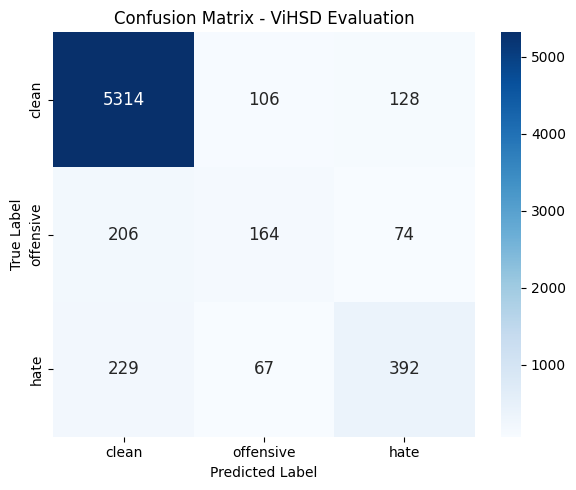

Đã lưu biểu đồ ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint01/confusion_matrix_checkpoint01.png


In [29]:
# Định nghĩa trực tiếp hàm vẽ ma trận nhầm lẫn và lưu biểu đồ
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint01.png')

import matplotlib.pyplot as plt
import seaborn as sns


# Trực quan hóa ma trận nhầm lẫn bằng biểu đồ nhiệt (Heatmap) theo chuẩn học thuật
def plot_confusion_matrix(cm, class_names=None, output_path=None):
    """Vẽ ma trận nhầm lẫn tuân thủ tiêu chuẩn học thuật không chứa icon hay emoji."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        df_cm,
        annot=True,
        cmap='Blues',
        fmt='d',
        cbar=True,
        ax=ax,
        annot_kws={'size': 12},
    )
    ax.set_title('Confusion Matrix - ViHSD Evaluation')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300)
    return fig


fig = plot_confusion_matrix(results['confusion_matrix'], class_names=class_names, output_path=cm_output_path)
plt.show()

print(f'Đã lưu biểu đồ ma trận nhầm lẫn tại: {cm_output_path}')

## 10. Xuất Kết Quả Đánh Giá, Ma Trận Nhầm Lẫn và Tệp Dự Đoán (Artifacts Export)

In [ ]:
# Cấu hình đường dẫn lưu trữ các tệp kết quả đầu ra
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

# Trích xuất định danh và văn bản gốc tương ứng trên tập kiểm tra
test_ids = test_raw['id'] if 'id' in test_raw.columns else list(range(len(test_y)))
test_texts = test_raw['free_text'].tolist() if len(test_raw) == len(test_y) else test_X

# 1. Xuất tệp kết quả dự đoán predictions.csv (gồm: id, text, ground_truth, predicted_label)
df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_texts,
    'ground_truth': y_true,
    'predicted_label': y_pred
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path} ({len(df_predictions)} mẫu)')

# 2. Xuất dữ liệu ma trận nhầm lẫn dạng bảng tính CSV
df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

# 3. Xuất tệp điểm số tổng hợp cốt lõi (evaluation_scores.csv)
from sklearn.metrics import accuracy_score, precision_score, recall_score

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

# 4. Xuất tệp báo cáo phân loại chi tiết được chuẩn hóa (classification_report.csv)
report_dict = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support'])
    })

# Thêm hàng accuracy tổng thể với support là tổng số mẫu kiểm tra
rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true)
})

# Thêm các hàng chỉ số trung bình (macro avg và weighted avg)
for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support'])
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

print('\nBảng điểm số tổng kết:')
print(df_scores.to_string(index=False))

print('\nBảng phân loại chi tiết:')
print(df_report.to_string(index=False))